# 04c — Classification of EGFR Compounds as Active or Inactive

## Project Overview

This notebook extends the EGFR machine learning workflow from continuous
pIC50 regression to binary classification of inhibitory activity.

The same 10,381 EGFR compounds used in the earlier notebooks are labeled
active or inactive from their experimental IC50 values. Morgan
fingerprints calculated from the canonical SMILES represent each
molecule, using the same radius and fingerprint length as the
descriptor and fingerprint notebooks.

Several potency cutoffs are compared. The cutoff that best separates
active from inactive compounds under scaffold cross-validation is used
to train and evaluate the classification models.

## Objectives

1. Load the curated EGFR activity dataset used throughout the project.
2. Inspect the IC50 and pIC50 distributions.
3. Compare candidate activity thresholds on scaffold-held training data.
4. Label each compound active or inactive at the selected threshold.
5. Represent each molecule with a 2,048-bit Morgan fingerprint.
6. Train logistic regression, random forest, and gradient boosting classifiers.
7. Evaluate the classifiers on scaffolds withheld from threshold selection and training.
8. Export the activity labels, performance tables, and trained models.

## Dataset

- **Target:** Epidermal Growth Factor Receptor (EGFR)
- **Compounds:** 10,381 molecules with canonical SMILES
- **Activity measurement:** Median IC50 (nM), expressed as pIC50
- **Molecular representation:** Morgan fingerprint, radius 2, 2,048 bits
- **Label:** Active or inactive
- **Evaluation:** Scaffold holdout and scaffold cross-validation
- **Metrics:** MCC, balanced accuracy, F1, ROC-AUC, precision, and recall

## Expected Outputs

- Comparison of candidate IC50 thresholds
- Active and inactive labels for the EGFR compound set
- Trained classification models
- Scaffold-holdout performance table
- Confusion matrix and ROC curves


## 1. Environment Setup and Library Imports

Required Python libraries are imported for dataset handling, molecular
fingerprints, classification models, evaluation, and figure export.
RDKit generates the Morgan fingerprints. scikit-learn trains and
evaluates the classifiers.


In [1]:
# Data handling
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Molecular fingerprints and scaffolds
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

# Classification models
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

# Project directory
PROJECT_ROOT = Path("..").resolve()

# Candidate potency cutoffs, in pIC50 units.
# pIC50 6.0 corresponds to an IC50 of 1 µM.
CANDIDATE_THRESHOLDS = [5.0, 5.5, 6.0, 6.5, 7.0, 7.5]
MINORITY_FRACTION_MIN = 0.15
RANDOM_STATE = 42

print("Project directory:", PROJECT_ROOT)
print("EGFR activity classification environment ready.")


Project directory: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery
EGFR activity classification environment ready.


## 2. EGFR Dataset Loading

The curated EGFR activity dataset is loaded from the processed data
directory. Each row is one compound. Median IC50 is the aggregated
experimental measurement, and pIC50 is the continuous potency value
used by the earlier regression models.

pIC50 is related to the median IC50 by:

pIC50 = 9 - log10(median IC50 in nM)

Loading this table keeps the classification labels aligned with the
molecules already used for fingerprint models, descriptor models, and
candidate screening.


In [2]:
data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "egfr_molecule_activity_with_smiles.csv"
)

df = pd.read_csv(data_path).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values:")
display(df.isnull().sum())


Dataset shape: (10381, 8)

Columns:
['molecule_chembl_id', 'median_ic50_nM', 'n_measurements', 'min_ic50_nM', 'max_ic50_nM', 'pIC50', 'canonical_smiles', 'valid_smiles']


,molecule_chembl_id,median_ic50_nM,n_measurements,min_ic50_nM,max_ic50_nM,pIC50,canonical_smiles,valid_smiles
0,CHEMBL10,53000.0,2,10000.0,96000.0,4.275724,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,True
1,CHEMBL1009,2880.0,1,2880.0,2880.0,5.540608,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,True
2,CHEMBL101253,457.7,1,457.7,457.7,6.339419,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,True
3,CHEMBL1016,3276.9,1,3276.9,3276.9,5.484537,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,True
4,CHEMBL101683,7300.0,1,7300.0,7300.0,5.136677,O=C(Nc1ccc(Cl)cc1)c1ccccc1NCc1ccncc1,True



Missing values:


molecule_chembl_id    0
median_ic50_nM        0
n_measurements        0
min_ic50_nM           0
max_ic50_nM           0
pIC50                 0
canonical_smiles      0
valid_smiles          0
dtype: int64

In [3]:
# Confirm that stored pIC50 values match the median IC50.
pic50_from_ic50 = 9 - np.log10(df["median_ic50_nM"])
max_difference = np.max(np.abs(pic50_from_ic50 - df["pIC50"]))

print("Compounds:", len(df))
print("Valid SMILES flags:", int(df["valid_smiles"].sum()))
print("Maximum pIC50 reconstruction difference:", max_difference)
print("\npIC50 summary:")
display(df["pIC50"].describe())
print("\nMedian IC50 (nM):", df["median_ic50_nM"].median())


Compounds: 10381
Valid SMILES flags: 10381
Maximum pIC50 reconstruction difference: 1.7763568394002505e-15

pIC50 summary:


count    10381.000000
mean         6.933809
std          1.305907
min          4.000000
25%          5.998266
50%          6.995679
75%          7.929962
max         11.000000
Name: pIC50, dtype: float64


Median IC50 (nM): 101.0


## 3. IC50 and pIC50 Distribution

The distribution of experimental potency was examined before any
activity label was assigned. pIC50 is used for the histogram because
the earlier models were trained on that scale. Higher pIC50 values
correspond to lower IC50 values and therefore greater inhibitory potency.

The median potency of this compound set locates a natural point of
comparison for the candidate thresholds in the next section.


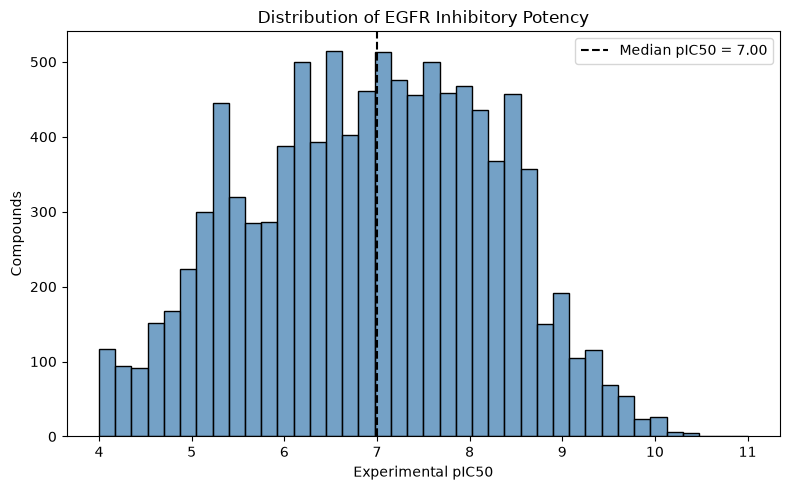

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_pic50_distribution.png
pIC50 minimum: 4.0
pIC50 maximum: 11.0
Median IC50 (nM): 101.0


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df["pIC50"],
    bins=40,
    color="steelblue",
    ax=ax,
)

median_pic50 = float(df["pIC50"].median())
ax.axvline(
    median_pic50,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Median pIC50 = {median_pic50:.2f}",
)

ax.set_xlabel("Experimental pIC50")
ax.set_ylabel("Compounds")
ax.set_title("Distribution of EGFR Inhibitory Potency")
ax.legend()

plt.tight_layout()

figure_path = PROJECT_ROOT / "figures" / "activity_pic50_distribution.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("pIC50 minimum:", df["pIC50"].min())
print("pIC50 maximum:", df["pIC50"].max())
print("Median IC50 (nM):", df["median_ic50_nM"].median())


## 4. Candidate Activity Thresholds

Six potency cutoffs were defined on the pIC50 scale. Each cutoff is
one half-log unit apart. A compound is counted as active when its
pIC50 is greater than or equal to the cutoff, which means its median
IC50 is less than or equal to the matching concentration.

The 1 µM cutoff (pIC50 6.0) is included because it is the conventional
ChEMBL definition of an active compound. The remaining cutoffs place
that convention in the context of this EGFR set, whose median IC50 is
near 100 nM.

This table describes the full compound set. It is not yet the model-based
choice of threshold. Threshold selection in a later section uses only
the scaffold training partition.


In [5]:
def ic50_nm_from_pic50(pic50_threshold):
    """Convert a pIC50 cutoff to an IC50 cutoff in nM."""
    return 10 ** (9 - pic50_threshold)


balance_rows = []

for threshold in CANDIDATE_THRESHOLDS:
    active_mask = df["pIC50"] >= threshold
    n_active = int(active_mask.sum())
    n_inactive = int((~active_mask).sum())
    ic50_nm = ic50_nm_from_pic50(threshold)

    balance_rows.append({
        "pIC50 Threshold": threshold,
        "IC50 Cutoff (nM)": round(ic50_nm, 1),
        "IC50 Cutoff (µM)": round(ic50_nm / 1000, 3),
        "Active": n_active,
        "Inactive": n_inactive,
        "Active Fraction": n_active / len(df),
        "Minority Fraction": min(n_active, n_inactive) / len(df),
    })

class_balance = pd.DataFrame(balance_rows)

display(class_balance.style.format({
    "pIC50 Threshold": "{:.1f}",
    "IC50 Cutoff (nM)": "{:,.1f}",
    "IC50 Cutoff (µM)": "{:.3f}",
    "Active Fraction": "{:.1%}",
    "Minority Fraction": "{:.1%}",
}))


,pIC50 Threshold,IC50 Cutoff (nM),IC50 Cutoff (µM),Active,Inactive,Active Fraction,Minority Fraction
0,5.0,"10,000.0",10.000,9635,746,92.8%,7.2%
1,5.5,"3,162.3",3.162,8598,1783,82.8%,17.2%
2,6.0,"1,000.0",1.000,7783,2598,75.0%,25.0%
3,6.5,316.2,0.316,6517,3864,62.8%,37.2%
4,7.0,100.0,0.100,5184,5197,49.9%,49.9%
5,7.5,31.6,0.032,3794,6587,36.5%,36.5%


## 5. Morgan Fingerprint Representation

Each canonical SMILES string was converted to an RDKit molecule and
then to a Morgan fingerprint. The fingerprint settings match the
representation used for the earlier EGFR models:

- Radius: 2
- Fingerprint length: 2,048 bits

Bemis–Murcko scaffolds were calculated from the same molecules so that
compounds sharing a core structure can be kept together during
splitting and cross-validation.


In [6]:
molecules = [
    Chem.MolFromSmiles(smiles)
    for smiles in df["canonical_smiles"]
]

print("Total molecules:", len(molecules))
print("Valid molecules:", sum(mol is not None for mol in molecules))

assert all(mol is not None for mol in molecules)

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
)

fingerprints = [
    morgan_generator.GetFingerprint(mol)
    for mol in molecules
]

X = np.zeros((len(fingerprints), 2048), dtype=np.uint8)

for i, fingerprint in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fingerprint, X[i])

print("Fingerprint matrix shape:", X.shape)
print("Fingerprint radius: 2")
print("Fingerprint length:", X.shape[1])
print("Mean bits set per compound:", X.sum(axis=1).mean().round(1))


Total molecules: 10381
Valid molecules: 10381


Fingerprint matrix shape: (10381, 2048)
Fingerprint radius: 2
Fingerprint length: 2048
Mean bits set per compound: 62.4


In [7]:
def get_scaffold(mol):
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False,
    )


scaffolds = np.array([
    get_scaffold(mol)
    for mol in molecules
])

print("Compounds:", len(scaffolds))
print("Unique scaffolds:", len(set(scaffolds)))


Compounds: 10381
Unique scaffolds: 3698


## 6. Scaffold Holdout for Threshold Selection

A scaffold-based partition was created before any activity threshold
was chosen. GroupShuffleSplit assigned every compound from a given
Bemis–Murcko scaffold to either the training partition or the test
partition.

The training partition is used to compare candidate thresholds and to
fit the final classifiers. The test partition is reserved for a single
evaluation after the threshold and the models have been fixed. Shared
scaffold count between the two partitions is reported to confirm that
the holdout is structurally disjoint.


In [8]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(X, df["pIC50"], groups=scaffolds)
)

train_scaffolds = set(scaffolds[train_idx])
test_scaffolds = set(scaffolds[test_idx])

print("Training compounds:", len(train_idx))
print("Testing compounds:", len(test_idx))
print("Training scaffolds:", len(train_scaffolds))
print("Testing scaffolds:", len(test_scaffolds))
print("Shared scaffolds:", len(train_scaffolds & test_scaffolds))


Training compounds: 8416
Testing compounds: 1965
Training scaffolds: 2958
Testing scaffolds: 740
Shared scaffolds: 0


## 7. Selection of the Activity Threshold

Each candidate cutoff was scored with a random forest trained on the
Morgan fingerprints. Scoring used three-fold GroupKFold inside the
scaffold training partition, so no test scaffold contributed to the
choice of threshold. The same forest settings were used at every cutoff.

Matthews correlation coefficient (MCC) was the selection metric.
MCC summarizes how well both the active and inactive labels are
recovered. Balanced accuracy was recorded as the tie-break. Accuracy
and F1 are reported alongside them because they describe overall
hits and the active class, and they rise when almost every compound
is labeled active.

A cutoff stayed eligible when each class made up at least 15% of the
training compounds. The eligible cutoff with the highest mean MCC was
selected.


In [9]:
def binary_scores(y_true, y_pred, y_prob):
    """Score one active/inactive prediction."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


X_dev = X[train_idx]
scaffolds_dev = scaffolds[train_idx]
pic50_dev = df["pIC50"].to_numpy()[train_idx]

group_kfold = GroupKFold(n_splits=3)
threshold_rows = []

for threshold in CANDIDATE_THRESHOLDS:
    y_dev = (pic50_dev >= threshold).astype(int)
    active_fraction = float(y_dev.mean())
    minority_fraction = min(active_fraction, 1 - active_fraction)

    print(
        f"Evaluating pIC50 >= {threshold:.1f} "
        f"(training active fraction {active_fraction:.1%})"
    )

    fold_scores = []

    for fold_train, fold_valid in group_kfold.split(
        X_dev,
        y_dev,
        groups=scaffolds_dev,
    ):
        forest = RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        forest.fit(X_dev[fold_train], y_dev[fold_train])

        y_pred = forest.predict(X_dev[fold_valid])
        y_prob = forest.predict_proba(X_dev[fold_valid])[:, 1]
        fold_scores.append(binary_scores(y_dev[fold_valid], y_pred, y_prob))

    fold_table = pd.DataFrame(fold_scores)
    ic50_nm = ic50_nm_from_pic50(threshold)

    threshold_rows.append({
        "pIC50 Threshold": threshold,
        "IC50 Cutoff (nM)": round(ic50_nm, 1),
        "IC50 Cutoff (µM)": round(ic50_nm / 1000, 3),
        "Training Active Fraction": active_fraction,
        "Minority Fraction": minority_fraction,
        "Eligible": minority_fraction >= MINORITY_FRACTION_MIN,
        "MCC": fold_table["MCC"].mean(),
        "MCC SD": fold_table["MCC"].std(ddof=1),
        "Balanced Accuracy": fold_table["Balanced Accuracy"].mean(),
        "Balanced Accuracy SD": fold_table["Balanced Accuracy"].std(ddof=1),
        "F1": fold_table["F1"].mean(),
        "ROC-AUC": fold_table["ROC-AUC"].mean(),
        "Accuracy": fold_table["Accuracy"].mean(),
    })

threshold_results = pd.DataFrame(threshold_rows)

eligible_results = threshold_results[
    threshold_results["Eligible"]
].sort_values(
    ["MCC", "Balanced Accuracy"],
    ascending=False,
)

best_threshold = float(eligible_results.iloc[0]["pIC50 Threshold"])
best_ic50_nm = ic50_nm_from_pic50(best_threshold)

display(threshold_results.style.format({
    "pIC50 Threshold": "{:.1f}",
    "IC50 Cutoff (nM)": "{:,.1f}",
    "IC50 Cutoff (µM)": "{:.3f}",
    "Training Active Fraction": "{:.1%}",
    "Minority Fraction": "{:.1%}",
    "MCC": "{:.3f}",
    "MCC SD": "{:.3f}",
    "Balanced Accuracy": "{:.3f}",
    "Balanced Accuracy SD": "{:.3f}",
    "F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "Accuracy": "{:.3f}",
}))

print("\nSelected pIC50 threshold:", best_threshold)
print(
    "Active: pIC50 >= "
    f"{best_threshold:.1f} (IC50 <= {best_ic50_nm:.1f} nM)"
)
print(
    "Inactive: pIC50 < "
    f"{best_threshold:.1f} (IC50 > {best_ic50_nm:.1f} nM)"
)


Evaluating pIC50 >= 5.0 (training active fraction 92.6%)


Evaluating pIC50 >= 5.5 (training active fraction 82.5%)


Evaluating pIC50 >= 6.0 (training active fraction 74.3%)


Evaluating pIC50 >= 6.5 (training active fraction 61.6%)


Evaluating pIC50 >= 7.0 (training active fraction 48.5%)


Evaluating pIC50 >= 7.5 (training active fraction 35.4%)


,pIC50 Threshold,IC50 Cutoff (nM),IC50 Cutoff (µM),Training Active Fraction,Minority Fraction,Eligible,MCC,MCC SD,Balanced Accuracy,Balanced Accuracy SD,F1,ROC-AUC,Accuracy
0,5.0,"10,000.0",10.000,92.6%,7.4%,False,0.376,0.011,0.641,0.019,0.963,0.916,0.930
1,5.5,"3,162.3",3.162,82.5%,17.5%,True,0.453,0.023,0.689,0.027,0.918,0.878,0.860
2,6.0,"1,000.0",1.000,74.3%,25.7%,True,0.539,0.044,0.750,0.033,0.891,0.881,0.833
3,6.5,316.2,0.316,61.6%,38.4%,True,0.602,0.034,0.793,0.022,0.854,0.881,0.815
4,7.0,100.0,0.100,48.5%,48.5%,True,0.583,0.048,0.790,0.024,0.785,0.874,0.792
5,7.5,31.6,0.032,35.4%,35.4%,True,0.570,0.061,0.775,0.024,0.711,0.877,0.808



Selected pIC50 threshold: 6.5
Active: pIC50 >= 6.5 (IC50 <= 316.2 nM)
Inactive: pIC50 < 6.5 (IC50 > 316.2 nM)


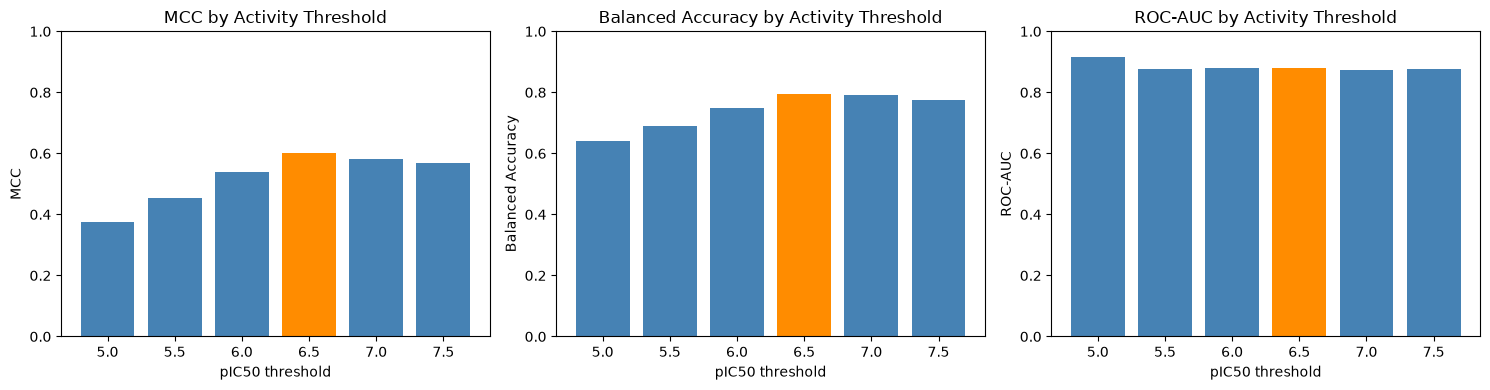

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_threshold_comparison.png
Highlighted threshold: 6.5


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_metrics = ["MCC", "Balanced Accuracy", "ROC-AUC"]
threshold_labels = [
    f"{threshold:.1f}"
    for threshold in threshold_results["pIC50 Threshold"]
]
bar_colors = [
    "darkorange" if threshold == best_threshold else "steelblue"
    for threshold in threshold_results["pIC50 Threshold"]
]

for ax, metric in zip(axes, plot_metrics):
    ax.bar(threshold_labels, threshold_results[metric], color=bar_colors)
    ax.set_title(f"{metric} by Activity Threshold")
    ax.set_xlabel("pIC50 threshold")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)

plt.tight_layout()

figure_path = (
    PROJECT_ROOT / "figures" / "activity_threshold_comparison.png"
)
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Highlighted threshold:", best_threshold)


## 8. Active and Inactive Labels

Scaffold cross-validation selected a pIC50 threshold of 6.5, equivalent
to an IC50 cutoff of 316.2 nM (0.316 µM). Compounds at or above this
threshold were labeled active. Compounds below it were labeled inactive.

On the IC50 scale, active compounds are those whose median inhibitory
concentration is at or below the selected cutoff. Inactive compounds
are those whose median IC50 is above that cutoff.

The label counts below include both the training and test partitions.
Model fitting still uses only the training partition.


In [11]:
df["activity_class"] = (
    df["pIC50"] >= best_threshold
).astype(int)

df["activity_label"] = np.where(
    df["activity_class"] == 1,
    "active",
    "inactive",
)

df["split"] = "train"
df.loc[test_idx, "split"] = "test"
df["scaffold"] = scaffolds

label_counts = (
    df.groupby(["split", "activity_label"])
    .size()
    .unstack(fill_value=0)
)

print(
    f"Label rule: active if pIC50 >= {best_threshold:.1f} "
    f"(IC50 <= {best_ic50_nm:.1f} nM); otherwise inactive."
)
print("\nLabel counts:")
display(label_counts)

print("\nFull dataset:")
print(df["activity_label"].value_counts().to_string())
print(
    "Active fraction:",
    f"{df['activity_class'].mean():.1%}",
)


Label rule: active if pIC50 >= 6.5 (IC50 <= 316.2 nM); otherwise inactive.

Label counts:


activity_label,active,inactive
split,,
test,1330,635
train,5187,3229



Full dataset:
activity_label
active      6517
inactive    3864
Active fraction: 62.8%


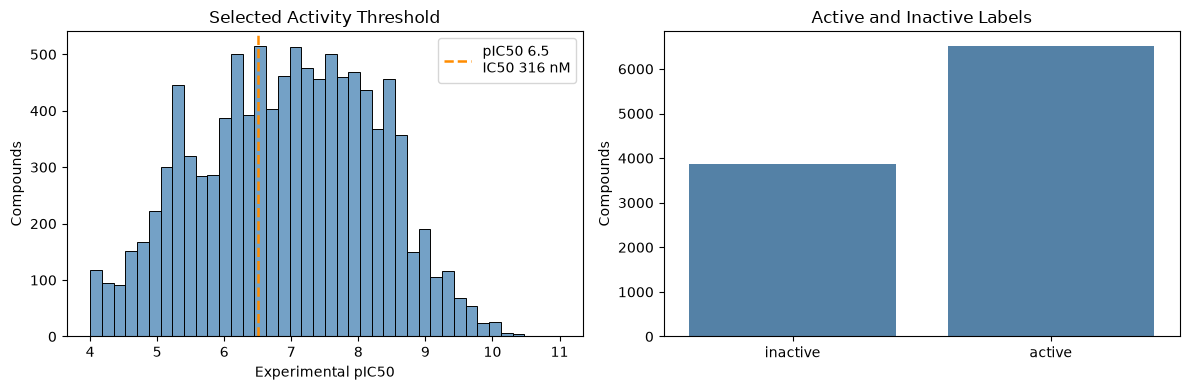

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_class_labels.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df["pIC50"],
    bins=40,
    color="steelblue",
    ax=axes[0],
)
axes[0].axvline(
    best_threshold,
    color="darkorange",
    linestyle="--",
    linewidth=1.8,
    label=(
        f"pIC50 {best_threshold:.1f}\n"
        f"IC50 {best_ic50_nm:.0f} nM"
    ),
)
axes[0].set_xlabel("Experimental pIC50")
axes[0].set_ylabel("Compounds")
axes[0].set_title("Selected Activity Threshold")
axes[0].legend()

sns.countplot(
    data=df,
    x="activity_label",
    order=["inactive", "active"],
    color="steelblue",
    ax=axes[1],
)
axes[1].set_xlabel("")
axes[1].set_ylabel("Compounds")
axes[1].set_title("Active and Inactive Labels")

plt.tight_layout()

figure_path = PROJECT_ROOT / "figures" / "activity_class_labels.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)


## 9. Classification Model Training

Three classifiers were trained on the Morgan fingerprints of the
scaffold training compounds, using the active and inactive labels
from the selected threshold.

Logistic regression provides a linear baseline. The random forest
matches the algorithm family used for the earlier pIC50 models and
for the threshold comparison. Histogram gradient boosting provides a
second nonlinear model that can use the full fingerprint width.

Class weights were balanced so that the inactive compounds influenced
the fit in proportion to the active compounds. Preprocessing was not
required: the fingerprint bits are already on a common 0/1 scale, and
the scaffold split was completed before fitting.

Performance was calculated once on the held-out scaffolds.


In [13]:
y = df["activity_class"].to_numpy()
X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

classification_rows = []
trained_models = {}
test_predictions = {}
test_probabilities = {}

for name, model in classifiers.items():
    print(f"Training {name}...")
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    scores = binary_scores(y_test, y_pred, y_prob)
    scores["Model"] = name
    scores["Training Time (s)"] = round(elapsed, 2)
    classification_rows.append(scores)

    trained_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

classification_results = pd.DataFrame(classification_rows)
classification_results["pIC50 Threshold"] = best_threshold
classification_results["IC50 Cutoff (nM)"] = round(best_ic50_nm, 1)

metric_order = [
    "Model",
    "MCC",
    "Balanced Accuracy",
    "F1",
    "ROC-AUC",
    "Precision",
    "Recall",
    "Accuracy",
    "Training Time (s)",
    "pIC50 Threshold",
    "IC50 Cutoff (nM)",
]

classification_results = classification_results[metric_order].sort_values(
    ["MCC", "Balanced Accuracy"],
    ascending=False,
).reset_index(drop=True)

best_model_name = classification_results.loc[0, "Model"]

display(classification_results.style.format({
    "MCC": "{:.3f}",
    "Balanced Accuracy": "{:.3f}",
    "F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "Precision": "{:.3f}",
    "Recall": "{:.3f}",
    "Accuracy": "{:.3f}",
    "Training Time (s)": "{:.2f}",
    "pIC50 Threshold": "{:.1f}",
    "IC50 Cutoff (nM)": "{:,.1f}",
}))

print("Primary classifier:", best_model_name)


Training Logistic Regression...


Training Random Forest...


Training Gradient Boosting...


,Model,MCC,Balanced Accuracy,F1,ROC-AUC,Precision,Recall,Accuracy,Training Time (s),pIC50 Threshold,IC50 Cutoff (nM)
0,Random Forest,0.648,0.818,0.890,0.905,0.876,0.904,0.848,4.04,6.5,316.2
1,Gradient Boosting,0.594,0.802,0.864,0.893,0.879,0.850,0.819,26.49,6.5,316.2
2,Logistic Regression,0.558,0.785,0.850,0.860,0.869,0.832,0.802,2.89,6.5,316.2


Primary classifier: Random Forest


## 10. Classifier Comparison

Held-out scaffold performance was compared across the three classifiers.
MCC, balanced accuracy, F1, and ROC-AUC are shown together so that
agreement among the metrics can be inspected.

The classifier with the highest MCC on the scaffold test set is the
primary active/inactive model. Balanced accuracy breaks a tie.


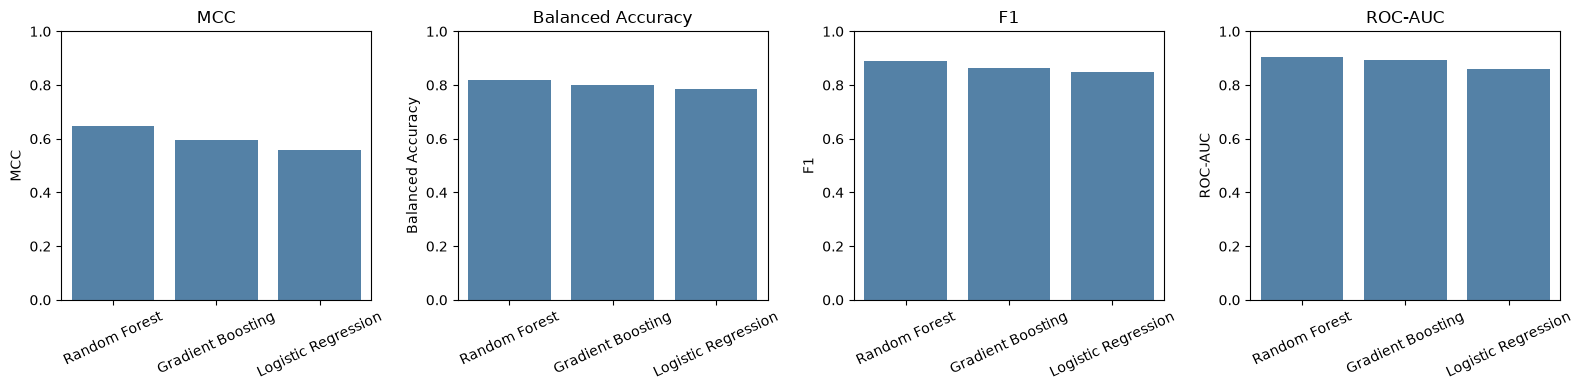

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_classification_comparison.png


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

comparison_metrics = ["MCC", "Balanced Accuracy", "F1", "ROC-AUC"]

for ax, metric in zip(axes, comparison_metrics):
    sns.barplot(
        data=classification_results,
        x="Model",
        y=metric,
        ax=ax,
        color="steelblue",
    )
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

figure_path = (
    PROJECT_ROOT / "figures" / "activity_classification_comparison.png"
)
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)


## 11. Confusion Matrix and ROC Curves

The primary classifier was examined with a confusion matrix on the
held-out scaffolds. Rows are the experimental activity labels and
columns are the predicted labels.

ROC curves for all three classifiers are shown on the same axes.
The dashed diagonal is the curve expected from a classifier that
does not separate active from inactive compounds. A curve that bows
toward the upper left indicates better ranking of potent compounds.


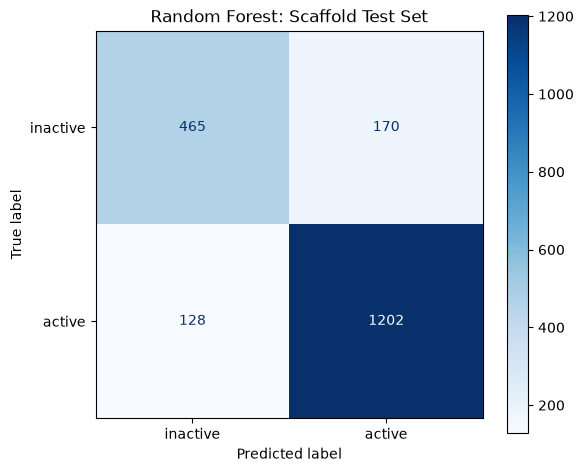

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_confusion_matrix.png
Primary classifier: Random Forest


In [15]:
best_predictions = test_predictions[best_model_name]

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["inactive", "active"],
    cmap="Blues",
    ax=ax,
)
ax.set_title(f"{best_model_name}: Scaffold Test Set")

plt.tight_layout()

figure_path = PROJECT_ROOT / "figures" / "activity_confusion_matrix.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Primary classifier:", best_model_name)


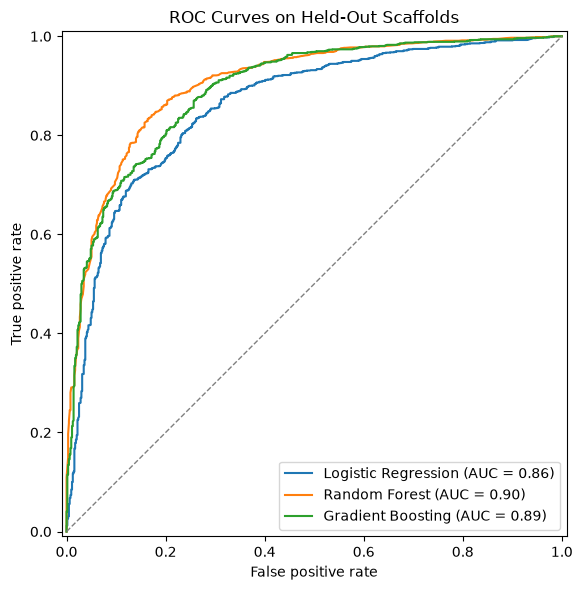

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/activity_roc_curves.png


In [16]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax,
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_title("ROC Curves on Held-Out Scaffolds")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")

plt.tight_layout()

figure_path = PROJECT_ROOT / "figures" / "activity_roc_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)


## 12. Model and Results Export

The activity labels, threshold comparison, classifier metrics, and
trained models were saved for later use. The label table records the
selected cutoff, the active or inactive assignment, the Bemis–Murcko
scaffold, and the scaffold split.

The random forest had the highest Matthews correlation coefficient on
the held-out scaffolds and was retained as the primary classifier.
All three fitted models are saved so the comparison can be reloaded
without retraining.


In [17]:
models_dir = PROJECT_ROOT / "results" / "models"
results_dir = PROJECT_ROOT / "results"

models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

model_filenames = {
    "Logistic Regression": "egfr_morgan_logreg_activity.joblib",
    "Random Forest": "egfr_morgan_rf_activity.joblib",
    "Gradient Boosting": "egfr_morgan_gb_activity.joblib",
}

for name, filename in model_filenames.items():
    joblib.dump(trained_models[name], models_dir / filename)

primary_path = models_dir / "egfr_morgan_activity_classifier.joblib"
joblib.dump(trained_models[best_model_name], primary_path)

threshold_results.to_csv(
    results_dir / "activity_threshold_comparison.csv",
    index=False,
)
classification_results.to_csv(
    results_dir / "activity_classification_results.csv",
    index=False,
)

label_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "median_ic50_nM",
    "pIC50",
    "activity_label",
    "activity_class",
    "scaffold",
    "split",
]

labeled_compounds = df[label_columns].copy()
labeled_compounds["pic50_threshold"] = best_threshold
labeled_compounds["ic50_cutoff_nM"] = round(best_ic50_nm, 1)
labeled_compounds.to_csv(
    results_dir / "egfr_activity_labels.csv",
    index=False,
)

print("Primary classifier:", best_model_name)
print("Saved model:", primary_path)
print("Activity labels:", results_dir / "egfr_activity_labels.csv")
print("Threshold table:", results_dir / "activity_threshold_comparison.csv")
print("Classification table:", results_dir / "activity_classification_results.csv")
print(
    f"Label rule retained: active if pIC50 >= {best_threshold:.1f} "
    f"(IC50 <= {best_ic50_nm:.1f} nM)."
)


Primary classifier: Random Forest
Saved model: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/models/egfr_morgan_activity_classifier.joblib
Activity labels: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/egfr_activity_labels.csv
Threshold table: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/activity_threshold_comparison.csv
Classification table: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/activity_classification_results.csv
Label rule retained: active if pIC50 >= 6.5 (IC50 <= 316.2 nM).


## 13. Summary

Experimental IC50 values for the 10,381 EGFR compounds were converted
to active and inactive labels. The activity threshold was chosen by
scaffold cross-validation on Morgan fingerprints, using Matthews
correlation coefficient as the selection metric. Cutoffs that left
either class below 15% of the training compounds were excluded.

The selected threshold was pIC50 6.5, or median IC50 ≤ 316.2 nM.
This cutoff labeled 6,517 compounds active (62.8%) and 3,864 compounds
inactive (37.2%). The conventional 1 µM cutoff (pIC50 6.0) was included
in the same comparison and had a lower cross-validated MCC (0.539
versus 0.602 at pIC50 6.5).

On 1,965 compounds from 740 scaffolds withheld from both threshold
selection and training, the random forest was the strongest classifier.

| Model | MCC | Balanced accuracy | F1 | ROC-AUC |
|---|---:|---:|---:|---:|
| Random Forest | 0.648 | 0.818 | 0.890 | 0.905 |
| Gradient Boosting | 0.594 | 0.802 | 0.864 | 0.893 |
| Logistic Regression | 0.558 | 0.785 | 0.850 | 0.860 |

The random forest correctly classified 1,202 of 1,330 active test
compounds and 465 of 635 inactive test compounds. The fitted model
is saved at `results/models/egfr_morgan_activity_classifier.joblib`.
